# Lab 05 - Sequence Models: RNN, LSTM và GRU

## 11. Experiment 1 - Xem qua dataset

In [35]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

def get_split_dir():
    candidates = [
        "datasets/splits",
        "../lab04/datasets/splits",
        "lab04/datasets/splits"
    ]
    for path in candidates:
        if os.path.exists(os.path.join(path, "train.csv")):
            return path
    raise FileNotFoundError("Split directory not found")

split_dir = get_split_dir()
df_train = pd.read_csv(os.path.join(split_dir, "train.csv"))
df_val = pd.read_csv(os.path.join(split_dir, "val.csv"))
df_test = pd.read_csv(os.path.join(split_dir, "test.csv"))

In [36]:
train_counts = df_train["label"].value_counts()
val_counts = df_val["label"].value_counts()
test_counts = df_test["label"].value_counts()

dataset_summary = pd.DataFrame({
    "Train Samples": train_counts,
    "Train (%)": (train_counts / len(df_train) * 100).round(2),
    "Val Samples": val_counts,
    "Val (%)": (val_counts / len(df_val) * 100).round(2),
    "Test Samples": test_counts,
    "Test (%)": (test_counts / len(df_test) * 100).round(2)
})

total_row = pd.Series({
    "Train Samples": len(df_train),
    "Train (%)": 100.0,
    "Val Samples": len(df_val),
    "Val (%)": 100.0,
    "Test Samples": len(df_test),
    "Test (%)": 100.0
}, name="Total")

dataset_summary = pd.concat([dataset_summary, pd.DataFrame([total_row])])
display(dataset_summary)
print(f"Number of classes: {df_train['label'].nunique()} ({list(df_train['label'].unique())})")

,Train Samples,Train (%),Val Samples,Val (%),Test Samples,Test (%)
pos,17419.0,50.19,3732.0,50.18,3733.0,50.19
neg,17288.0,49.81,3705.0,49.82,3705.0,49.81
Total,34707.0,100.00,7437.0,100.00,7438.0,100.00


Number of classes: 2 (['pos', 'neg'])


In [37]:
integrity_records = []
for name, df in [("Train", df_train), ("Val", df_val), ("Test", df_test)]:
    missing_text = df["text"].isna().sum() + (df["text"].astype(str).str.strip() == "").sum()
    missing_label = df["label"].isna().sum()
    internal_duplicates = df["text"].duplicated().sum()
    integrity_records.append({
        "Split": name,
        "Total Samples": len(df),
        "Missing Text": missing_text,
        "Missing Label": missing_label,
        "Duplicates": internal_duplicates
    })

cross_train_val = len(set(df_train["text"]).intersection(set(df_val["text"])))
cross_train_test = len(set(df_train["text"]).intersection(set(df_test["text"])))
cross_val_test = len(set(df_val["text"]).intersection(set(df_test["text"])))

integrity_df = pd.DataFrame(integrity_records)
display(integrity_df)
print(f"Cross-split duplicates (Train-Val): {cross_train_val}")
print(f"Cross-split duplicates (Train-Test): {cross_train_test}")
print(f"Cross-split duplicates (Val-Test): {cross_val_test}")

,Split,Total Samples,Missing Text,Missing Label,Duplicates
0,Train,34707,0,0,0
1,Val,7437,0,0,0
2,Test,7438,0,0,0


Cross-split duplicates (Train-Val): 0
Cross-split duplicates (Train-Test): 0
Cross-split duplicates (Val-Test): 0


In [38]:
df_train["seq_len"] = df_train["text"].astype(str).str.split().str.len()
df_val["seq_len"] = df_val["text"].astype(str).str.split().str.len()
df_test["seq_len"] = df_test["text"].astype(str).str.split().str.len()

stats_records = []
for name, df in [("Train", df_train), ("Val", df_val), ("Test", df_test)]:
    s = df["seq_len"]
    stats_records.append({
        "Split": name,
        "Min Length": int(s.min()),
        "Median Length": float(s.median()),
        "Mean Length": round(float(s.mean()), 2),
        "Max Length": int(s.max()),
        "Std Dev": round(float(s.std()), 2)
    })

stats_df = pd.DataFrame(stats_records)
display(stats_df)

,Split,Min Length,Median Length,Mean Length,Max Length,Std Dev
0,Train,4,173.0,231.72,2470,172.25
1,Val,10,170.0,229.90,2125,172.06
2,Test,8,176.0,231.09,1475,167.69


In [39]:
percentiles = [50, 75, 80, 85, 90, 95, 98, 99]
perc_values = np.percentile(df_train["seq_len"], percentiles)

percentile_df = pd.DataFrame({
    "Percentile": [f"p{p}" for p in percentiles],
    "Sequence Length (tokens)": perc_values.astype(int),
    "Coverage (%)": percentiles
})
display(percentile_df)

,Percentile,Sequence Length (tokens),Coverage (%)
0,p50,173,50
1,p75,280,75
2,p80,320,80
3,p85,373,85
4,p90,454,90
5,p95,594,95
6,p98,783,98
7,p99,906,99


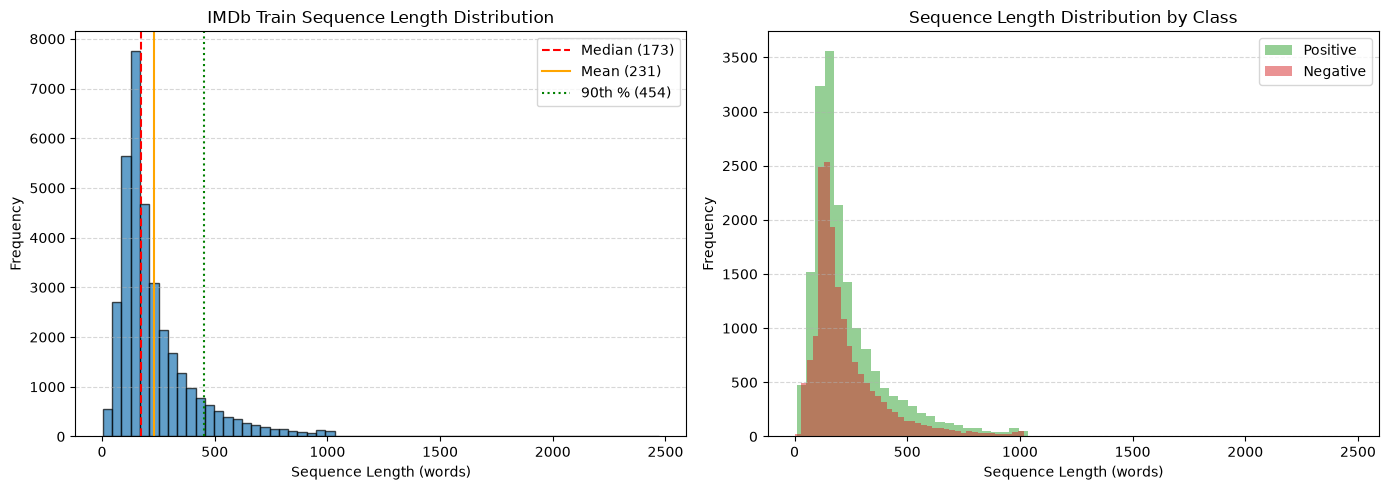

In [40]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].hist(df_train["seq_len"], bins=60, color="#1f77b4", edgecolor="black", alpha=0.7)
axes[0].axvline(df_train["seq_len"].median(), color="red", linestyle="--", linewidth=1.5, label=f"Median ({int(df_train['seq_len'].median())})")
axes[0].axvline(df_train["seq_len"].mean(), color="orange", linestyle="-", linewidth=1.5, label=f"Mean ({int(df_train['seq_len'].mean())})")
axes[0].axvline(np.percentile(df_train["seq_len"], 90), color="green", linestyle=":", linewidth=1.5, label=f"90th % ({int(np.percentile(df_train['seq_len'], 90))})")
axes[0].set_title("IMDb Train Sequence Length Distribution")
axes[0].set_xlabel("Sequence Length (words)")
axes[0].set_ylabel("Frequency")
axes[0].legend()
axes[0].grid(axis="y", linestyle="--", alpha=0.5)

axes[1].hist(df_train[df_train["label"] == "pos"]["seq_len"], bins=60, alpha=0.5, color="#2ca02c", label="Positive")
axes[1].hist(df_train[df_train["label"] == "neg"]["seq_len"], bins=60, alpha=0.5, color="#d62728", label="Negative")
axes[1].set_title("Sequence Length Distribution by Class")
axes[1].set_xlabel("Sequence Length (words)")
axes[1].set_ylabel("Frequency")
axes[1].legend()
axes[1].grid(axis="y", linestyle="--", alpha=0.5)

plt.tight_layout()
plt.savefig("sequence_length_histogram.png", dpi=300)
plt.show()

Câu hỏi: Nếu phải chọn max_length thì nên dựa vào thông tin nào?

Trước tiên nên nhìn phân phối độ dài câu. Dữ liệu IMDb lệch phải khá nhiều: bài ngắn nhất 4 từ, trung vị 173 từ, trung bình khoảng 232 từ, nhưng có bài dài tới 2470 từ. Các mốc percentile: p75 là 280, p80 là 320, p90 là 454, p95 là 594.

Nếu muốn giữ gần hết nội dung thì chọn khoảng p80 đến p90, tức là 320 đến 450 từ. Không nên lấy theo bài dài nhất vì khi đó hầu hết câu sẽ toàn padding.

Tiếp theo là chi phí. max_length càng lớn thì train càng lâu, tốn bộ nhớ hơn, và câu ngắn bị pad thêm nhiều số 0.

Cũng phải tính tới mô hình. Simple RNN không nhớ được chuỗi dài vì vanishing gradient, nên để max_length lớn cũng không được lợi nhiều. LSTM và GRU có cổng nên chịu được chuỗi dài hơn.

Cuối cùng là cắt đầu hay cắt đuôi. Review phim hay chốt ý ở cuối bài, nên có thể thử cắt phần đầu (pre-truncation) thay vì cắt phần đuôi như mặc định.

## 12. Tokenization và vocabulary

Các bước xử lý: raw text -> tokenizer -> token id -> padding/truncation -> embedding -> sequence model

- PAD có id 0, dùng để đệm cho câu ngắn đủ độ dài, không mang nghĩa gì.
- UNK có id 1, dùng cho từ không có trong vocab.
- Padding là thêm số 0 vào câu ngắn cho đủ max_length.
- Truncation là cắt bớt phần thừa của câu dài hơn max_length.

In [41]:
import re
from collections import Counter

def tokenize(text):
    text = re.sub(r"<[^>]+>", " ", str(text).lower())
    return re.findall(r"\b\w+\b", text)

token_counter = Counter()
for text in df_train["text"]:
    token_counter.update(tokenize(text))

vocab = {"<PAD>": 0, "<UNK>": 1}
for word, count in token_counter.most_common(20000):
    vocab[word] = len(vocab)

def encode_text(text, max_len, vocab_dict, trunc="post", pad="post"):
    tokens = tokenize(text)
    ids = [vocab_dict.get(t, 1) for t in tokens]
    if len(ids) > max_len:
        ids = ids[:max_len] if trunc == "post" else ids[-max_len:]
    else:
        pad_width = max_len - len(ids)
        ids = ids + [0] * pad_width if pad == "post" else [0] * pad_width + ids
    return ids

In [42]:
sample_text = "I really like this movie"
tokens = tokenize(sample_text)
token_ids = [vocab.get(t, 1) for t in tokens]
padded_ids = encode_text(sample_text, max_len=8, vocab_dict=vocab, pad="post")
truncated_ids = encode_text(sample_text, max_len=3, vocab_dict=vocab, trunc="post")

print(f"Original Text: {sample_text}")
print(f"Tokens: {tokens}")
print(f"Token IDs: {token_ids}")
print(f"Padded (max_len=8): {padded_ids}")
print(f"Truncated (max_len=3): {truncated_ids}")

Original Text: I really like this movie
Tokens: ['i', 'really', 'like', 'this', 'movie']
Token IDs: [10, 64, 38, 11, 16]
Padded (max_len=8): [10, 64, 38, 11, 16, 0, 0, 0]
Truncated (max_len=3): [10, 64, 38]


## 13. Experiment 2 - Padding và truncation

In [43]:
total_tokens = df_train["text"].apply(lambda x: len(tokenize(x))).sum()

retention_data = []
for m in [50, 100, 200]:
    retained_tokens = df_train["text"].apply(lambda x: min(len(tokenize(x)), m)).sum()
    pct = round(retained_tokens / total_tokens * 100, 2)
    retention_data.append({"Max Length": m, "% Tokens Retained": pct})

retention_df = pd.DataFrame(retention_data)
display(retention_df)

,Max Length,% Tokens Retained
0,50,21.10
1,100,40.81
2,200,67.94


In [44]:
import time
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset
from sklearn.metrics import accuracy_score, f1_score

class SequenceRNN(nn.Module):
    def __init__(self, vocab_size, embed_dim=64, hidden_dim=64):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, embed_dim, padding_idx=0)
        self.rnn = nn.RNN(embed_dim, hidden_dim, batch_first=True)
        self.fc = nn.Linear(hidden_dim, 1)

    def forward(self, x):
        emb = self.embedding(x)
        _, h_n = self.rnn(emb)
        return self.fc(h_n.squeeze(0)).squeeze(-1)

y_train = (df_train["label"] == "pos").astype(np.float32).values
y_val = (df_val["label"] == "pos").astype(np.float32).values
y_test = (df_test["label"] == "pos").astype(np.float32).values

In [45]:
exp2_results = []

for max_len in [50, 100, 200]:
    X_train_enc = torch.tensor([encode_text(t, max_len, vocab) for t in df_train["text"]], dtype=torch.long)
    X_test_enc = torch.tensor([encode_text(t, max_len, vocab) for t in df_test["text"]], dtype=torch.long)

    train_loader = DataLoader(
        TensorDataset(X_train_enc, torch.tensor(y_train, dtype=torch.float32)),
        batch_size=256,
        shuffle=True
    )
    test_loader = DataLoader(
        TensorDataset(X_test_enc, torch.tensor(y_test, dtype=torch.float32)),
        batch_size=256,
        shuffle=False
    )

    torch.manual_seed(42)
    model = SequenceRNN(vocab_size=len(vocab), embed_dim=64, hidden_dim=64)
    criterion = nn.BCEWithLogitsLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=0.003)

    t0 = time.time()
    model.train()
    for epoch in range(2):
        for bx, by in train_loader:
            optimizer.zero_grad()
            logits = model(bx)
            loss = criterion(logits, by)
            loss.backward()
            optimizer.step()
    train_time = round(time.time() - t0, 2)

    model.eval()
    preds = []
    with torch.no_grad():
        for bx, _ in test_loader:
            logits = model(bx)
            p = (torch.sigmoid(logits) >= 0.5).int().cpu().numpy()
            preds.extend(p)

    acc = round(float(accuracy_score(y_test, preds)), 4)
    f1 = round(float(f1_score(y_test, preds)), 4)

    retained_pct = retention_df.loc[retention_df["Max Length"] == max_len, "% Tokens Retained"].values[0]

    exp2_results.append({
        "Max Length": max_len,
        "% Tokens Retained": retained_pct,
        "Training Time (s)": train_time,
        "Accuracy": acc,
        "F1": f1
    })

results_df = pd.DataFrame(exp2_results)
display(results_df)

,Max Length,% Tokens Retained,Training Time (s),Accuracy,F1
0,50,21.10,5.54,0.5247,0.4968
1,100,40.81,8.08,0.6100,0.5599
2,200,67.94,18.27,0.5110,0.5235


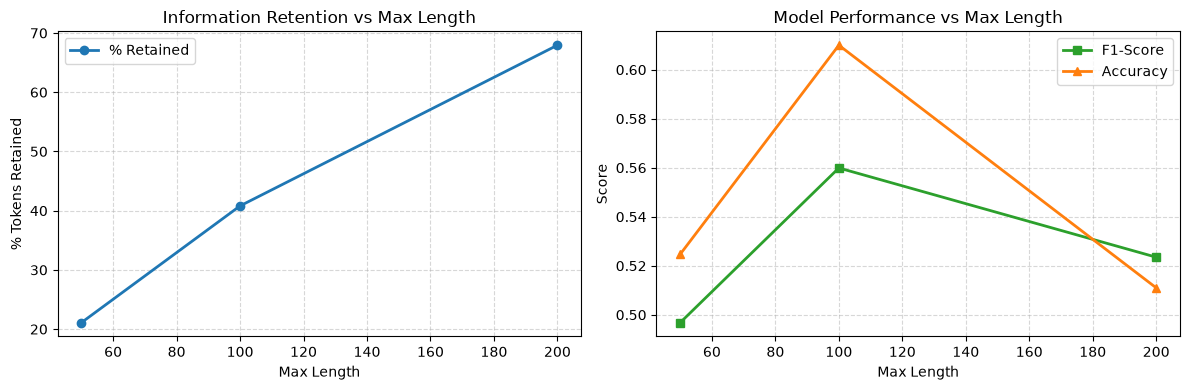

In [46]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(results_df["Max Length"], results_df["% Tokens Retained"], marker="o", color="#1f77b4", linewidth=2, label="% Retained")
axes[0].set_title("Information Retention vs Max Length")
axes[0].set_xlabel("Max Length")
axes[0].set_ylabel("% Tokens Retained")
axes[0].grid(True, linestyle="--", alpha=0.5)
axes[0].legend()

axes[1].plot(results_df["Max Length"], results_df["F1"], marker="s", color="#2ca02c", linewidth=2, label="F1-Score")
axes[1].plot(results_df["Max Length"], results_df["Accuracy"], marker="^", color="#ff7f0e", linewidth=2, label="Accuracy")
axes[1].set_title("Model Performance vs Max Length")
axes[1].set_xlabel("Max Length")
axes[1].set_ylabel("Score")
axes[1].grid(True, linestyle="--", alpha=0.5)
axes[1].legend()

plt.tight_layout()
plt.savefig("padding_truncation_experiment.png", dpi=300)
plt.show()

Câu hỏi 1: Tăng max_length có luôn làm performance tốt hơn không?

Không. Với Simple RNN trong thí nghiệm này:
- max_length 50: giữ 21.1% token, F1 0.4968, train 5.5s
- max_length 100: giữ 40.8% token, F1 0.5599, train 8.1s
- max_length 200: giữ 67.9% token, F1 0.5235, train 18.3s

Từ 50 lên 100 thì F1 có tăng, nhưng lên 200 thì lại giảm, trong khi thời gian train tăng hơn gấp đôi.

Mình nghĩ có hai lý do. Một là Simple RNN bị vanishing gradient, chuỗi càng dài thì càng khó nhớ phần đầu. Hai là code đang dùng post-padding và lấy hidden state cuối cùng, nên câu ngắn sẽ phải đi qua rất nhiều token PAD trước khi ra output, thông tin thật bị loãng đi.

Cũng nên lưu ý là F1 của RNN ở đây đều khá thấp, gần mức đoán ngẫu nhiên, nên chênh lệch giữa các mức có thể một phần do train chưa ổn định.

Câu hỏi 2: Nếu max_length quá nhỏ thì mất loại thông tin nào?

- Phần kết luận ở cuối review, chỗ người viết hay nói rõ phim hay hay dở.
- Những câu chuyển ý kiểu "hình ảnh đẹp nhưng cốt truyện chán", cắt sớm thì chỉ còn vế đầu nghe như khen.
- Ngữ cảnh chung của cả bài, ví dụ các nhận xét về diễn xuất, kịch bản nằm ở giữa bài.

## 14. Simple RNN cell

Công thức: h_t = tanh(W_xh * x_t + W_hh * h_(t-1) + b_h)

- x_t: vector của từ ở bước t
- h_(t-1): hidden state ở bước trước
- W_xh, W_hh: ma trận trọng số cho input và cho hidden state
- b_h: bias

Ở mỗi bước, cell lấy từ hiện tại và hidden state cũ, nhân với trọng số, cộng lại rồi cho qua tanh để ra hidden state mới.

In [47]:
from rnn_cell import SimpleRNNCell, verify_against_pytorch

cell = SimpleRNNCell(input_size=4, hidden_size=3)
sample_x = np.array([0.5, -0.2, 0.1, 0.8])
sample_h = np.zeros(3)
sample_next_h = cell.forward(sample_x, sample_h)

passed, max_diff = verify_against_pytorch()
print(f"Computed next hidden state shape: {sample_next_h.shape}")
print(f"Validation against torch.nn.RNNCell passed: {passed} (max diff: {max_diff:.2e})")

Computed next hidden state shape: (3, 1)
Validation against torch.nn.RNNCell passed: True (max diff: 9.10e-08)


## 15. Experiment 3 - Baseline

So sánh 2 mô hình:
1. TF-IDF + Logistic Regression (baseline từ lab 04)
2. Embedding + Simple RNN + lớp Linear

Mục tiêu là xem RNN có tận dụng được thứ tự từ, thứ mà TF-IDF bỏ qua, hay không.

In [48]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

t0 = time.time()
tfidf_vec = TfidfVectorizer(max_features=20000)
X_train_tfidf = tfidf_vec.fit_transform(df_train["text"])
X_test_tfidf = tfidf_vec.transform(df_test["text"])

clf_lr = LogisticRegression(max_iter=1000, random_state=42)
clf_lr.fit(X_train_tfidf, (df_train["label"] == "pos").astype(int))
lr_train_time = round(time.time() - t0, 2)

lr_preds = clf_lr.predict(X_test_tfidf)
lr_acc = round(float(accuracy_score(y_test, lr_preds)), 4)
lr_prec = round(float(precision_score(y_test, lr_preds)), 4)
lr_rec = round(float(recall_score(y_test, lr_preds)), 4)
lr_f1 = round(float(f1_score(y_test, lr_preds)), 4)

In [49]:
class BaselineRNN(nn.Module):
    def __init__(self, vocab_size=len(vocab), embed_dim=64, hidden_dim=64):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, embed_dim, padding_idx=0)
        self.rnn = nn.RNN(embed_dim, hidden_dim, batch_first=True)
        self.fc = nn.Linear(hidden_dim, 1)

    def forward(self, x):
        emb = self.embedding(x)
        _, h_n = self.rnn(emb)
        return self.fc(h_n.squeeze(0)).squeeze(-1)

seq_len = 50
X_tr_base = torch.tensor([encode_text(t, seq_len, vocab) for t in df_train["text"]], dtype=torch.long)
X_te_base = torch.tensor([encode_text(t, seq_len, vocab) for t in df_test["text"]], dtype=torch.long)

loader_train = DataLoader(TensorDataset(X_tr_base, torch.tensor(y_train, dtype=torch.float32)), batch_size=256, shuffle=True)
loader_test = DataLoader(TensorDataset(X_te_base, torch.tensor(y_test, dtype=torch.float32)), batch_size=256, shuffle=False)

torch.manual_seed(42)
rnn_baseline = BaselineRNN()
criterion = nn.BCEWithLogitsLoss()
optimizer = torch.optim.Adam(rnn_baseline.parameters(), lr=0.003)

t0 = time.time()
rnn_baseline.train()
for epoch in range(2):
    for bx, by in loader_train:
        optimizer.zero_grad()
        logits = rnn_baseline(bx)
        loss = criterion(logits, by)
        loss.backward()
        optimizer.step()
rnn_train_time = round(time.time() - t0, 2)

rnn_baseline.eval()
rnn_preds = []
with torch.no_grad():
    for bx, _ in loader_test:
        logits = rnn_baseline(bx)
        p = (torch.sigmoid(logits) >= 0.5).int().cpu().numpy()
        rnn_preds.extend(p)

rnn_acc = round(float(accuracy_score(y_test, rnn_preds)), 4)
rnn_prec = round(float(precision_score(y_test, rnn_preds)), 4)
rnn_rec = round(float(recall_score(y_test, rnn_preds)), 4)
rnn_f1 = round(float(f1_score(y_test, rnn_preds)), 4)

In [50]:
baseline_comparison = pd.DataFrame([
    {
        "Model": "Logistic Regression",
        "Representation": "TF-IDF",
        "Accuracy": lr_acc,
        "Precision": lr_prec,
        "Recall": lr_rec,
        "F1": lr_f1,
        "Training time (s)": lr_train_time
    },
    {
        "Model": "RNN",
        "Representation": "Embedding",
        "Accuracy": rnn_acc,
        "Precision": rnn_prec,
        "Recall": rnn_rec,
        "F1": rnn_f1,
        "Training time (s)": rnn_train_time
    }
])
display(baseline_comparison)

,Model,Representation,Accuracy,Precision,Recall,F1,Training time (s)
0,Logistic Regression,TF-IDF,0.9024,0.8958,0.9116,0.9036,12.03
1,RNN,Embedding,0.5247,0.5301,0.4675,0.4968,5.24


In [51]:
test_pairs = [
    ("the movie was good not bad", "the movie was bad not good"),
    ("not terrible actually brilliant", "not brilliant actually terrible"),
    ("i liked it it was not boring", "i hated it it was not entertaining")
]

pair_results = []
for s1, s2 in test_pairs:
    v1 = tfidf_vec.transform([s1])
    v2 = tfidf_vec.transform([s2])
    p1_tfidf = clf_lr.predict_proba(v1)[0][1]
    p2_tfidf = clf_lr.predict_proba(v2)[0][1]

    t1 = torch.tensor([encode_text(s1, seq_len, vocab)], dtype=torch.long)
    t2 = torch.tensor([encode_text(s2, seq_len, vocab)], dtype=torch.long)
    with torch.no_grad():
        p1_rnn = float(torch.sigmoid(rnn_baseline(t1))[0])
        p2_rnn = float(torch.sigmoid(rnn_baseline(t2))[0])

    pair_results.append({
        "Sentence 1": s1,
        "Sentence 2": s2,
        "TF-IDF P(Pos) S1": round(p1_tfidf, 4),
        "TF-IDF P(Pos) S2": round(p2_tfidf, 4),
        "TF-IDF Delta": round(abs(p1_tfidf - p2_tfidf), 6),
        "RNN P(Pos) S1": round(p1_rnn, 4),
        "RNN P(Pos) S2": round(p2_rnn, 4),
        "RNN Delta": round(abs(p1_rnn - p2_rnn), 4)
    })

pair_df = pd.DataFrame(pair_results)
display(pair_df)

,Sentence 1,Sentence 2,TF-IDF P(Pos) S1,TF-IDF P(Pos) S2,TF-IDF Delta,RNN P(Pos) S1,RNN P(Pos) S2,RNN Delta
0,the movie was good not bad,the movie was bad not good,0.0070,0.007,0.000000,0.4837,0.4525,0.0312
1,not terrible actually brilliant,not brilliant actually terrible,0.1010,0.101,0.000000,0.4359,0.4549,0.0190
2,i liked it it was not boring,i hated it it was not entertaining,0.1041,0.623,0.518882,0.4353,0.4401,0.0048


In [52]:
np.random.seed(42)
sample_indices = np.random.choice(len(df_test), 1000, replace=False)
sample_texts = df_test["text"].iloc[sample_indices].tolist()
sample_labels = y_test[sample_indices]

def shuffle_text(t):
    words = t.split()
    np.random.shuffle(words)
    return " ".join(words)

shuffled_texts = [shuffle_text(t) for t in sample_texts]

orig_tfidf = tfidf_vec.transform(sample_texts)
shuf_tfidf = tfidf_vec.transform(shuffled_texts)
acc_orig_tfidf = accuracy_score(sample_labels, clf_lr.predict(orig_tfidf))
acc_shuf_tfidf = accuracy_score(sample_labels, clf_lr.predict(shuf_tfidf))

orig_tensors = torch.tensor([encode_text(t, seq_len, vocab) for t in sample_texts], dtype=torch.long)
shuf_tensors = torch.tensor([encode_text(t, seq_len, vocab) for t in shuffled_texts], dtype=torch.long)
with torch.no_grad():
    preds_orig_rnn = (torch.sigmoid(rnn_baseline(orig_tensors)) >= 0.5).int().numpy()
    preds_shuf_rnn = (torch.sigmoid(rnn_baseline(shuf_tensors)) >= 0.5).int().numpy()
acc_orig_rnn = accuracy_score(sample_labels, preds_orig_rnn)
acc_shuf_rnn = accuracy_score(sample_labels, preds_shuf_rnn)

shuffle_df = pd.DataFrame([
    {
        "Model": "Logistic Regression (TF-IDF)",
        "Original Accuracy": round(acc_orig_tfidf, 4),
        "Shuffled Accuracy": round(acc_shuf_tfidf, 4),
        "Accuracy Delta": round(acc_orig_tfidf - acc_shuf_tfidf, 4)
    },
    {
        "Model": "RNN (Embedding)",
        "Original Accuracy": round(acc_orig_rnn, 4),
        "Shuffled Accuracy": round(acc_shuf_rnn, 4),
        "Accuracy Delta": round(acc_orig_rnn - acc_shuf_rnn, 4)
    }
])
display(shuffle_df)

,Model,Original Accuracy,Shuffled Accuracy,Accuracy Delta
0,Logistic Regression (TF-IDF),0.906,0.906,0.000
1,RNN (Embedding),0.518,0.522,-0.004


Câu hỏi: RNN có thực sự dùng thông tin thứ tự mà TF-IDF không dùng không?

Về lý thuyết thì có, vì RNN đọc từng từ theo thứ tự còn TF-IDF chỉ đếm từ. Nhưng kết quả của mình cho thấy Simple RNN ở đây tận dụng thông tin này rất ít.

Thử với cặp câu đảo thứ tự từ:
- "the movie was good not bad" và "the movie was bad not good" có cùng bộ từ nên TF-IDF cho xác suất giống hệt nhau (0.007), chênh lệch bằng 0.
- RNN cho 0.4837 và 0.4525. Có khác nhau nhưng chỉ chênh 0.03, và cả hai đều quanh 0.45, tức là mô hình gần như không chắc chắn câu nào.
- Cặp thứ hai RNN cũng chỉ chênh 0.019. Cặp thứ ba thực ra khác từ nên TF-IDF chênh tới 0.52, không dùng để so được.

Thử xáo trộn thứ tự từ trên 1000 câu test:
- TF-IDF giữ nguyên accuracy 0.906, đúng như mong đợi.
- RNN từ 0.518 thành 0.522, gần như không đổi.

Tóm lại, RNN có nhạy với thứ tự từ (output thay đổi khi đảo từ) còn TF-IDF thì hoàn toàn không. Nhưng Simple RNN của mình train chưa tốt, accuracy chỉ 0.5247, nên chưa khai thác được thông tin này. Nếu RNN thật sự dựa vào thứ tự thì accuracy phải giảm rõ khi xáo trộn từ.

TF-IDF + Logistic Regression vẫn tốt hơn hẳn với accuracy 0.9024, vì bài toán sentiment phụ thuộc nhiều vào từ khóa. Phần LSTM và GRU ở sau cho kết quả khả quan hơn.

## 16. LSTM và 18. GRU

LSTM có thêm cell state c_t và 3 cổng:
- forget gate: f_t = sigmoid(W_f [x_t, h_(t-1)] + b_f)
- input gate: i_t = sigmoid(W_i [x_t, h_(t-1)] + b_i)
- candidate: c~_t = tanh(W_c [x_t, h_(t-1)] + b_c)
- cập nhật cell state: c_t = f_t * c_(t-1) + i_t * c~_t
- output gate: o_t = sigmoid(W_o [x_t, h_(t-1)] + b_o)
- hidden state: h_t = o_t * tanh(c_t)

Cell state được cập nhật bằng phép cộng nên gradient truyền ngược dễ hơn, đỡ bị vanishing gradient.

GRU gọn hơn, không có cell state riêng và chỉ có 2 cổng:
- update gate: z_t = sigmoid(W_z [x_t, h_(t-1)] + b_z)
- reset gate: r_t = sigmoid(W_r [x_t, h_(t-1)] + b_r)
- candidate: h~_t = tanh(W [x_t, r_t * h_(t-1)] + b)
- hidden state: h_t = (1 - z_t) * h_(t-1) + z_t * h~_t

So sánh nhanh:
- Simple RNN: không có cổng, nhớ xa kém, ít tham số nhất.
- LSTM: 3 cổng và có cell state, nhớ xa tốt, nhiều tham số nhất (phần recurrent khoảng gấp 4 RNN).
- GRU: 2 cổng, nhớ xa tốt, số tham số ở giữa (phần recurrent khoảng gấp 3 RNN).

## 19. Experiment 4 - RNN vs LSTM vs GRU

Cả 3 mô hình được train với cùng điều kiện:
- vocab 20000 từ, embedding 64, hidden 64
- max_length 100, batch size 256
- Adam với lr 0.001, loss BCEWithLogitsLoss
- 10 epoch
- train 34707 mẫu, val 7437 mẫu, test 7438 mẫu

In [53]:
seq_len_exp4 = 100
batch_size_exp4 = 256

X_train_exp4 = torch.tensor([encode_text(t, seq_len_exp4, vocab) for t in df_train["text"]], dtype=torch.long)
X_val_exp4 = torch.tensor([encode_text(t, seq_len_exp4, vocab) for t in df_val["text"]], dtype=torch.long)
X_test_exp4 = torch.tensor([encode_text(t, seq_len_exp4, vocab) for t in df_test["text"]], dtype=torch.long)

y_train_tensor = torch.tensor(y_train, dtype=torch.float32)
y_val_tensor = torch.tensor(y_val, dtype=torch.float32)
y_test_tensor = torch.tensor(y_test, dtype=torch.float32)

train_loader_exp4 = DataLoader(TensorDataset(X_train_exp4, y_train_tensor), batch_size=batch_size_exp4, shuffle=True)
val_loader_exp4 = DataLoader(TensorDataset(X_val_exp4, y_val_tensor), batch_size=batch_size_exp4, shuffle=False)
test_loader_exp4 = DataLoader(TensorDataset(X_test_exp4, y_test_tensor), batch_size=batch_size_exp4, shuffle=False)

In [54]:
class SequenceClassifier(nn.Module):
    def __init__(self, cell_type, vocab_size, embed_dim=64, hidden_dim=64):
        super().__init__()
        self.cell_type = cell_type
        self.embedding = nn.Embedding(vocab_size, embed_dim, padding_idx=0)
        if cell_type == "RNN":
            self.rnn = nn.RNN(embed_dim, hidden_dim, batch_first=True)
        elif cell_type == "LSTM":
            self.rnn = nn.LSTM(embed_dim, hidden_dim, batch_first=True)
        elif cell_type == "GRU":
            self.rnn = nn.GRU(embed_dim, hidden_dim, batch_first=True)
        self.fc = nn.Linear(hidden_dim, 1)

    def forward(self, x):
        emb = self.embedding(x)
        out, h = self.rnn(emb)
        if self.cell_type == "LSTM":
            last_h = h[0].squeeze(0)
        else:
            last_h = h.squeeze(0)
        return self.fc(last_h).squeeze(-1)

In [55]:
num_epochs = 10
models = {}
histories = {}
exp4_metrics = []

for arch in ["RNN", "LSTM", "GRU"]:
    print(f"=== Training {arch} for {num_epochs} Epochs ===")
    torch.manual_seed(42)
    model = SequenceClassifier(arch, vocab_size=len(vocab), embed_dim=64, hidden_dim=64)
    param_count = sum(p.numel() for p in model.parameters())

    criterion = nn.BCEWithLogitsLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

    train_loss_history = []
    val_loss_history = []

    t0 = time.time()
    for epoch in range(1, num_epochs + 1):
        model.train()
        total_train_loss = 0.0
        for bx, by in train_loader_exp4:
            optimizer.zero_grad()
            logits = model(bx)
            loss = criterion(logits, by)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=5.0)
            optimizer.step()
            total_train_loss += loss.item() * len(bx)
        avg_train_loss = total_train_loss / len(df_train)

        model.eval()
        total_val_loss = 0.0
        with torch.no_grad():
            for bx, by in val_loader_exp4:
                logits = model(bx)
                loss = criterion(logits, by)
                total_val_loss += loss.item() * len(bx)
        avg_val_loss = total_val_loss / len(df_val)

        train_loss_history.append(avg_train_loss)
        val_loss_history.append(avg_val_loss)

        print(f"Epoch [{epoch:02d}/{num_epochs:02d}] - Train Loss: {avg_train_loss:.4f} | Val Loss: {avg_val_loss:.4f}")

    total_training_time = round(time.time() - t0, 2)
    models[arch] = model
    histories[arch] = {
        "train_loss": train_loss_history,
        "val_loss": val_loss_history
    }

    model.eval()
    test_preds = []
    with torch.no_grad():
        for bx, _ in test_loader_exp4:
            logits = model(bx)
            p = (torch.sigmoid(logits) >= 0.5).int().cpu().numpy()
            test_preds.extend(p)

    acc = round(float(accuracy_score(y_test, test_preds)), 4)
    prec = round(float(precision_score(y_test, test_preds)), 4)
    rec = round(float(recall_score(y_test, test_preds)), 4)
    f1 = round(float(f1_score(y_test, test_preds)), 4)

    exp4_metrics.append({
        "Model": arch,
        "Parameters": f"{param_count:,}",
        "Training time (s)": total_training_time,
        "Accuracy": acc,
        "Precision": prec,
        "Recall": rec,
        "F1": f1
    })

exp4_df = pd.DataFrame(exp4_metrics)
display(exp4_df)

=== Training RNN for 10 Epochs ===
Epoch [01/10] - Train Loss: 0.6958 | Val Loss: 0.6931
Epoch [02/10] - Train Loss: 0.6871 | Val Loss: 0.6913
Epoch [03/10] - Train Loss: 0.6685 | Val Loss: 0.6816
Epoch [04/10] - Train Loss: 0.6713 | Val Loss: 0.6821
Epoch [05/10] - Train Loss: 0.6425 | Val Loss: 0.6516
Epoch [06/10] - Train Loss: 0.6405 | Val Loss: 0.6532
Epoch [07/10] - Train Loss: 0.6165 | Val Loss: 0.6529
Epoch [08/10] - Train Loss: 0.6055 | Val Loss: 0.6555
Epoch [09/10] - Train Loss: 0.6091 | Val Loss: 0.6492
Epoch [10/10] - Train Loss: 0.5739 | Val Loss: 0.6665
=== Training LSTM for 10 Epochs ===
Epoch [01/10] - Train Loss: 0.6902 | Val Loss: 0.7004
Epoch [02/10] - Train Loss: 0.6748 | Val Loss: 0.6644
Epoch [03/10] - Train Loss: 0.6278 | Val Loss: 0.6216
Epoch [04/10] - Train Loss: 0.5707 | Val Loss: 0.5727
Epoch [05/10] - Train Loss: 0.5179 | Val Loss: 0.5263
Epoch [06/10] - Train Loss: 0.4577 | Val Loss: 0.4973
Epoch [07/10] - Train Loss: 0.4213 | Val Loss: 0.4759
Epoch [08/1

,Model,Parameters,Training time (s),Accuracy,Precision,Recall,F1
0,RNN,"1,288,513",43.96,0.6262,0.6096,0.7099,0.6559
1,LSTM,"1,313,473",76.77,0.8038,0.8380,0.7552,0.7944
2,GRU,"1,305,153",114.09,0.8330,0.8058,0.8792,0.8409


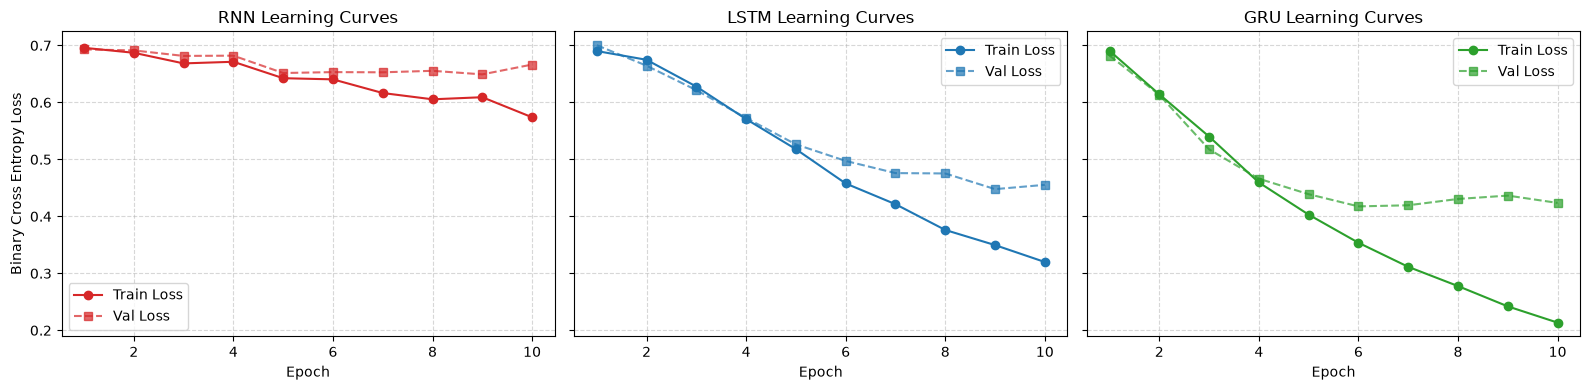

In [56]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4), sharey=True)
epochs_range = range(1, num_epochs + 1)

colors = {"RNN": "#d62728", "LSTM": "#1f77b4", "GRU": "#2ca02c"}

for i, arch in enumerate(["RNN", "LSTM", "GRU"]):
    axes[i].plot(epochs_range, histories[arch]["train_loss"], label="Train Loss", color=colors[arch], linestyle="-", marker="o")
    axes[i].plot(epochs_range, histories[arch]["val_loss"], label="Val Loss", color=colors[arch], linestyle="--", marker="s", alpha=0.7)
    axes[i].set_title(f"{arch} Learning Curves")
    axes[i].set_xlabel("Epoch")
    axes[i].set_ylabel("Binary Cross Entropy Loss" if i == 0 else "")
    axes[i].grid(True, linestyle="--", alpha=0.5)
    axes[i].legend()

plt.tight_layout()
plt.savefig("learning_curves.png", dpi=300)
plt.show()

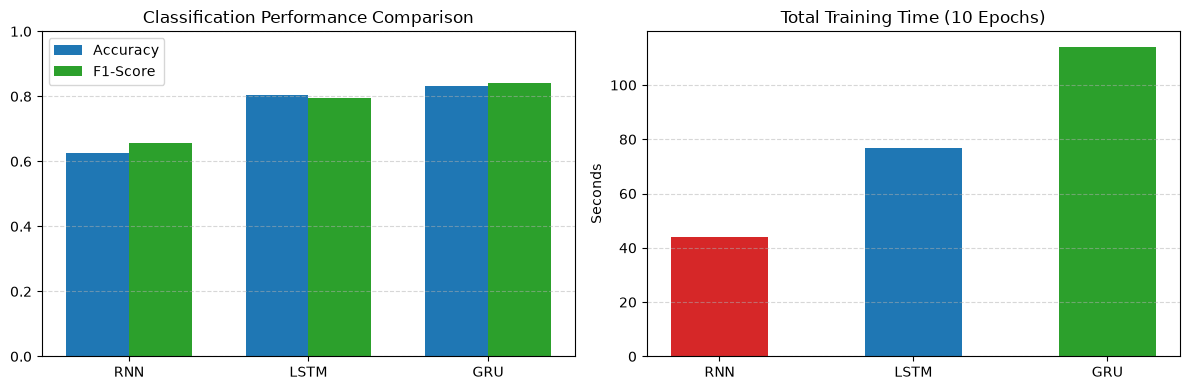

In [57]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

arch_names = exp4_df["Model"].tolist()
f1_scores = exp4_df["F1"].tolist()
acc_scores = exp4_df["Accuracy"].tolist()
times = exp4_df["Training time (s)"].tolist()

x_pos = np.arange(len(arch_names))
width = 0.35

axes[0].bar(x_pos - width/2, acc_scores, width, label="Accuracy", color="#1f77b4")
axes[0].bar(x_pos + width/2, f1_scores, width, label="F1-Score", color="#2ca02c")
axes[0].set_xticks(x_pos)
axes[0].set_xticklabels(arch_names)
axes[0].set_ylim(0.0, 1.0)
axes[0].set_title("Classification Performance Comparison")
axes[0].legend()
axes[0].grid(axis="y", linestyle="--", alpha=0.5)

axes[1].bar(arch_names, times, color=["#d62728", "#1f77b4", "#2ca02c"], width=0.5)
axes[1].set_title("Total Training Time (10 Epochs)")
axes[1].set_ylabel("Seconds")
axes[1].grid(axis="y", linestyle="--", alpha=0.5)

plt.tight_layout()
plt.savefig("rnn_lstm_gru_comparison.png", dpi=300)
plt.show()

Câu hỏi 1: Kết quả có giống dự đoán không?

Phần lớn là giống. LSTM và GRU tốt hơn Simple RNN rất nhiều:
- RNN: accuracy 0.6262, F1 0.6559
- LSTM: accuracy 0.8038, F1 0.7944
- GRU: accuracy 0.8330, F1 0.8409

Simple RNN học rất chậm, val loss cứ quanh 0.65 suốt 10 epoch. Lý do là vanishing gradient, qua 100 bước thì gradient về tới các từ đầu gần như không còn. LSTM và GRU có cổng nên giữ thông tin lâu hơn và học nhanh hơn hẳn.

Điểm hơi khác là GRU tốt hơn LSTM một chút. Theo lý thuyết hai mô hình này thường ngang nhau, ở đây có thể do GRU ít tham số hơn (1,305,153 so với 1,313,473) nên hội tụ nhanh hơn trong 10 epoch.

Câu hỏi 2: Ngoài accuracy cần xem thêm gì?

- Thời gian train: RNN 44s, LSTM 77s, GRU 114s. Lẽ ra GRU phải nhanh hơn LSTM vì ít phép tính hơn, mình chưa rõ nguyên nhân, có thể do máy lúc chạy, cần chạy lại vài lần mới chắc.
- Precision và recall: GRU có recall cao (0.8792) nhưng precision thấp hơn (0.8058), tức là nó hay đoán positive. LSTM thì ngược lại, precision 0.8380 và recall 0.7552.
- Overfitting: val loss của GRU thấp nhất ở epoch 6 (0.4175). Sau đó train loss vẫn giảm xuống 0.21 nhưng val loss tăng lên khoảng 0.42 đến 0.44, tức là GRU bắt đầu overfit từ epoch 6. LSTM thì val loss vẫn giảm tới epoch 9 nên chưa overfit rõ.

## 20. Experiment 5 - Sequence length

Giữ GRU cố định (mô hình tốt nhất ở trên), thử max_length 50, 100 và 200, mỗi lần train 3 epoch. Theo dõi phần trăm token giữ lại, thời gian train, val loss, accuracy và F1 trên tập test.

In [58]:
exp5_results = []
exp5_epochs = 3
best_arch = "GRU"

for m_len in [50, 100, 200]:
    X_tr_m = torch.tensor([encode_text(t, m_len, vocab) for t in df_train["text"]], dtype=torch.long)
    X_val_m = torch.tensor([encode_text(t, m_len, vocab) for t in df_val["text"]], dtype=torch.long)
    X_te_m = torch.tensor([encode_text(t, m_len, vocab) for t in df_test["text"]], dtype=torch.long)

    loader_tr_m = DataLoader(TensorDataset(X_tr_m, y_train_tensor), batch_size=256, shuffle=True)
    loader_val_m = DataLoader(TensorDataset(X_val_m, y_val_tensor), batch_size=256, shuffle=False)
    loader_te_m = DataLoader(TensorDataset(X_te_m, y_test_tensor), batch_size=256, shuffle=False)

    torch.manual_seed(42)
    model_m = SequenceClassifier(best_arch, vocab_size=len(vocab), embed_dim=64, hidden_dim=64)
    criterion_m = nn.BCEWithLogitsLoss()
    optimizer_m = torch.optim.Adam(model_m.parameters(), lr=0.001)

    t0 = time.time()
    val_loss_final = 0.0
    for epoch in range(1, exp5_epochs + 1):
        model_m.train()
        for bx, by in loader_tr_m:
            optimizer_m.zero_grad()
            logits = model_m(bx)
            loss = criterion_m(logits, by)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model_m.parameters(), max_norm=5.0)
            optimizer_m.step()

        model_m.eval()
        total_val_loss = 0.0
        with torch.no_grad():
            for bx, by in loader_val_m:
                logits = model_m(bx)
                loss = criterion_m(logits, by)
                total_val_loss += loss.item() * len(bx)
        val_loss_final = total_val_loss / len(df_val)

    training_time_m = round(time.time() - t0, 2)

    model_m.eval()
    preds_m = []
    with torch.no_grad():
        for bx, _ in loader_te_m:
            logits = model_m(bx)
            p = (torch.sigmoid(logits) >= 0.5).int().cpu().numpy()
            preds_m.extend(p)

    acc_m = round(float(accuracy_score(y_test, preds_m)), 4)
    f1_m = round(float(f1_score(y_test, preds_m)), 4)
    ret_pct = retention_df.loc[retention_df["Max Length"] == m_len, "% Tokens Retained"].values[0]

    exp5_results.append({
        "Model": f"{best_arch} (len={m_len})",
        "Max Length": m_len,
        "% Tokens Retained": ret_pct,
        "Validation Loss": round(val_loss_final, 4),
        "Training time (s)": training_time_m,
        "Test Accuracy": acc_m,
        "Test F1": f1_m
    })

exp5_df = pd.DataFrame(exp5_results)
display(exp5_df)

,Model,Max Length,% Tokens Retained,Validation Loss,Training time (s),Test Accuracy,Test F1
0,GRU (len=50),50,21.10,0.5256,17.59,0.7338,0.7526
1,GRU (len=100),100,40.81,0.5177,33.47,0.7507,0.7498
2,GRU (len=200),200,67.94,0.6376,71.75,0.6578,0.6969


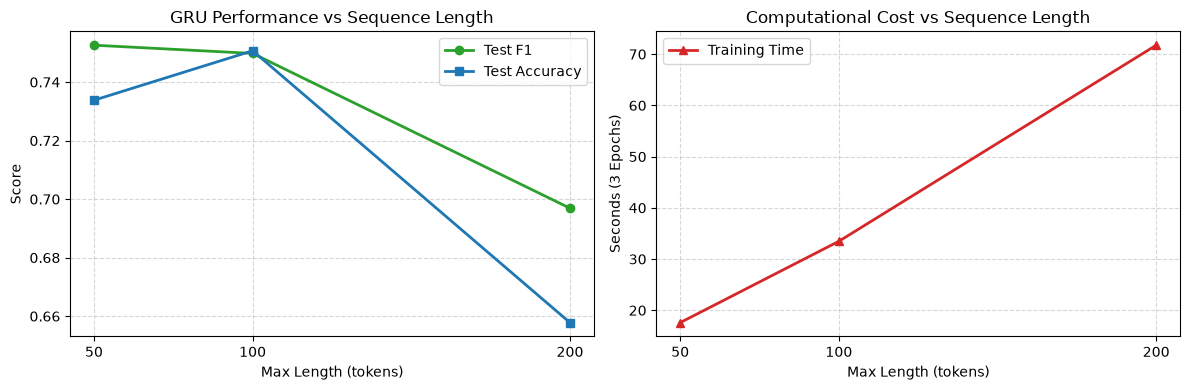

In [59]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

lens = exp5_df["Max Length"].tolist()
f1s = exp5_df["Test F1"].tolist()
accs = exp5_df["Test Accuracy"].tolist()
times = exp5_df["Training time (s)"].tolist()

axes[0].plot(lens, f1s, marker="o", color="#2ca02c", linewidth=2, label="Test F1")
axes[0].plot(lens, accs, marker="s", color="#1f77b4", linewidth=2, label="Test Accuracy")
axes[0].set_title("GRU Performance vs Sequence Length")
axes[0].set_xlabel("Max Length (tokens)")
axes[0].set_ylabel("Score")
axes[0].set_xticks(lens)
axes[0].grid(True, linestyle="--", alpha=0.5)
axes[0].legend()

axes[1].plot(lens, times, marker="^", color="#d62728", linewidth=2, label="Training Time")
axes[1].set_title("Computational Cost vs Sequence Length")
axes[1].set_xlabel("Max Length (tokens)")
axes[1].set_ylabel("Seconds (3 Epochs)")
axes[1].set_xticks(lens)
axes[1].grid(True, linestyle="--", alpha=0.5)
axes[1].legend()

plt.tight_layout()
plt.savefig("sequence_length_tradeoff.png", dpi=300)
plt.show()

Câu hỏi: Có trade-off giữa context và chi phí tính toán không?

Có. Thời gian train tăng gần gấp đôi mỗi lần tăng max_length: 17.6s, 33.5s rồi 71.8s.

Nhưng performance thì không tăng theo:
- max_length 50: accuracy 0.7338, F1 0.7526, val loss 0.5256
- max_length 100: accuracy 0.7507, F1 0.7498, val loss 0.5177
- max_length 200: accuracy 0.6578, F1 0.6969, val loss 0.6376

Từ 50 lên 100 accuracy tăng nhẹ, F1 gần như giữ nguyên. Lên 200 thì kết quả tệ hẳn dù giữ được tới 68% token.

Mình nghĩ có hai lý do. Một là chỉ train 3 epoch, chuỗi dài hơn thì cần nhiều epoch hơn mới hội tụ. Hai là post-padding: với max_length 200 thì phần lớn câu bị pad rất nhiều, mà mô hình lại lấy hidden state ở bước cuối cùng.

Với điều kiện hiện tại thì max_length 100 là hợp lý nhất, val loss thấp nhất và thời gian chỉ bằng một nửa so với 200.

## 21. Experiment 6 - Long-range dependency

Đặt từ cảm xúc quan trọng ở 3 vị trí trong câu: đầu, giữa và cuối, phần còn lại là các từ trung tính. Sau đó so sánh xác suất giữa câu positive và câu negative trên Simple RNN và GRU. Chênh lệch (delta) càng lớn thì mô hình càng nhận ra được từ đó.

In [60]:
dependency_test_cases = [
    {
        "Position": "Beginning",
        "Sentence Pos": "masterpiece was this film with many characters and scenes that developed over several years of production and history",
        "Sentence Neg": "terrible was this film with many characters and scenes that developed over several years of production and history"
    },
    {
        "Position": "Middle",
        "Sentence Pos": "the production team worked for several years creating an outstanding masterpiece with many characters and diverse scenes",
        "Sentence Neg": "the production team worked for several years creating an awful disaster with many characters and diverse scenes"
    },
    {
        "Position": "End",
        "Sentence Pos": "after many years of production and character development this entire film project was an absolute masterpiece",
        "Sentence Neg": "after many years of production and character development this entire film project was an absolute disaster"
    }
]

dep_records = []
rnn_trained = models["RNN"]
gru_trained = models["GRU"]

for case in dependency_test_cases:
    pos_text = case["Sentence Pos"]
    neg_text = case["Sentence Neg"]

    t_pos = torch.tensor([encode_text(pos_text, 100, vocab)], dtype=torch.long)
    t_neg = torch.tensor([encode_text(neg_text, 100, vocab)], dtype=torch.long)

    with torch.no_grad():
        p_pos_rnn = float(torch.sigmoid(rnn_trained(t_pos))[0])
        p_neg_rnn = float(torch.sigmoid(rnn_trained(t_neg))[0])
        delta_rnn = abs(p_pos_rnn - p_neg_rnn)

        p_pos_gru = float(torch.sigmoid(gru_trained(t_pos))[0])
        p_neg_gru = float(torch.sigmoid(gru_trained(t_neg))[0])
        delta_gru = abs(p_pos_gru - p_neg_gru)

    dep_records.append({
        "Keyword Position": case["Position"],
        "RNN P(Pos|Sent+)": round(p_pos_rnn, 4),
        "RNN P(Pos|Sent-)": round(p_neg_rnn, 4),
        "RNN Sensitivity (Delta)": round(delta_rnn, 4),
        "GRU P(Pos|Sent+)": round(p_pos_gru, 4),
        "GRU P(Pos|Sent-)": round(p_neg_gru, 4),
        "GRU Sensitivity (Delta)": round(delta_gru, 4)
    })

dep_df = pd.DataFrame(dep_records)
display(dep_df)

,Keyword Position,RNN P(Pos|Sent+),RNN P(Pos|Sent-),RNN Sensitivity (Delta),GRU P(Pos|Sent+),GRU P(Pos|Sent-),GRU Sensitivity (Delta)
0,Beginning,0.8107,0.3478,0.4629,0.9766,0.4161,0.5605
1,Middle,0.8107,0.8107,0.0000,0.9790,0.0177,0.9613
2,End,0.8107,0.3478,0.4629,0.9872,0.2271,0.7601


Nhận xét

Kết quả quan sát được:
- GRU: delta là 0.5605 khi từ khóa ở đầu, 0.9613 ở giữa và 0.7601 ở cuối. GRU phân biệt được ở cả 3 vị trí.
- Simple RNN: delta là 0.4629 ở đầu, 0 ở giữa và 0.4629 ở cuối. Câu positive nào RNN cũng cho đúng 0.8107, câu negative thì hoặc 0.3478 hoặc 0.8107. Nghĩa là RNN gần như chỉ cho ra vài giá trị cố định, không thực sự đọc từ khóa.

Giải thích:
- Simple RNN bị vanishing gradient nên khó học được tác động của từng từ cụ thể trong chuỗi.
- Một điểm quan trọng là các câu test chỉ khoảng 17 từ nhưng được pad lên 100, mà padding nằm ở cuối. Vì vậy từ khóa "ở cuối câu" thực ra vẫn cách bước cuối cùng hơn 80 token PAD. Thí nghiệm này chưa thật sự đo được ảnh hưởng của vị trí như mong muốn, mình nghĩ nên đổi sang pre-padding hoặc dùng pack_padded_sequence thì kết quả sẽ đúng ý hơn.
- GRU có update gate, khi z_t gần 0 thì h_t gần bằng h_(t-1), nên thông tin từ khóa được giữ lại qua nhiều bước PAD phía sau. Đây là lý do GRU vẫn phân biệt tốt.

## 22. Tổng hợp kết quả

Gộp kết quả của tất cả mô hình vào một bảng và lưu ra file results.csv.

In [61]:
all_results = [
    {
        "Model": "Logistic Regression",
        "Representation": "TF-IDF",
        "Parameters": "20,001",
        "Training time (s)": lr_train_time,
        "Accuracy": lr_acc,
        "Precision": lr_prec,
        "Recall": lr_rec,
        "F1": lr_f1
    },
    {
        "Model": "Simple RNN",
        "Representation": "Learned Embedding",
        "Parameters": exp4_df.loc[exp4_df["Model"] == "RNN", "Parameters"].values[0],
        "Training time (s)": exp4_df.loc[exp4_df["Model"] == "RNN", "Training time (s)"].values[0],
        "Accuracy": exp4_df.loc[exp4_df["Model"] == "RNN", "Accuracy"].values[0],
        "Precision": exp4_df.loc[exp4_df["Model"] == "RNN", "Precision"].values[0],
        "Recall": exp4_df.loc[exp4_df["Model"] == "RNN", "Recall"].values[0],
        "F1": exp4_df.loc[exp4_df["Model"] == "RNN", "F1"].values[0]
    },
    {
        "Model": "LSTM",
        "Representation": "Learned Embedding",
        "Parameters": exp4_df.loc[exp4_df["Model"] == "LSTM", "Parameters"].values[0],
        "Training time (s)": exp4_df.loc[exp4_df["Model"] == "LSTM", "Training time (s)"].values[0],
        "Accuracy": exp4_df.loc[exp4_df["Model"] == "LSTM", "Accuracy"].values[0],
        "Precision": exp4_df.loc[exp4_df["Model"] == "LSTM", "Precision"].values[0],
        "Recall": exp4_df.loc[exp4_df["Model"] == "LSTM", "Recall"].values[0],
        "F1": exp4_df.loc[exp4_df["Model"] == "LSTM", "F1"].values[0]
    },
    {
        "Model": "GRU",
        "Representation": "Learned Embedding",
        "Parameters": exp4_df.loc[exp4_df["Model"] == "GRU", "Parameters"].values[0],
        "Training time (s)": exp4_df.loc[exp4_df["Model"] == "GRU", "Training time (s)"].values[0],
        "Accuracy": exp4_df.loc[exp4_df["Model"] == "GRU", "Accuracy"].values[0],
        "Precision": exp4_df.loc[exp4_df["Model"] == "GRU", "Precision"].values[0],
        "Recall": exp4_df.loc[exp4_df["Model"] == "GRU", "Recall"].values[0],
        "F1": exp4_df.loc[exp4_df["Model"] == "GRU", "F1"].values[0]
    }
]

final_results_df = pd.DataFrame(all_results)
display(final_results_df)

final_results_df.to_csv("results.csv", index=False)
print("Saved all model comparison metrics to results.csv successfully!")

,Model,Representation,Parameters,Training time (s),Accuracy,Precision,Recall,F1
0,Logistic Regression,TF-IDF,"20,001",12.03,0.9024,0.8958,0.9116,0.9036
1,Simple RNN,Learned Embedding,"1,288,513",43.96,0.6262,0.6096,0.7099,0.6559
2,LSTM,Learned Embedding,"1,313,473",76.77,0.8038,0.8380,0.7552,0.7944
3,GRU,Learned Embedding,"1,305,153",114.09,0.8330,0.8058,0.8792,0.8409


Saved all model comparison metrics to results.csv successfully!


## 24. Confusion matrix

Vẽ confusion matrix trên tập test cho mô hình tốt nhất (GRU) để xem mô hình hay sai ở lớp nào.

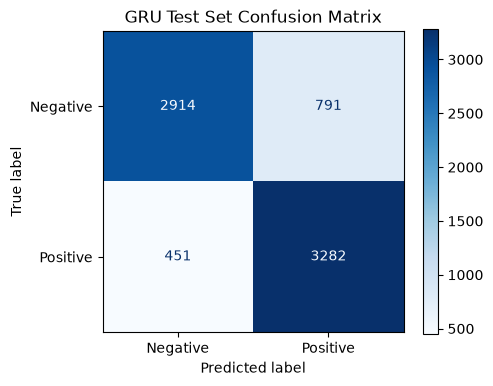

True Negatives: 2914, False Positives: 791
False Negatives: 451, True Positives: 3282
Precision: 0.8058, Recall: 0.8792


In [62]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

best_model = models["GRU"]
best_model.eval()

gru_test_preds = []
with torch.no_grad():
    for bx, _ in test_loader_exp4:
        logits = best_model(bx)
        p = (torch.sigmoid(logits) >= 0.5).int().cpu().numpy()
        gru_test_preds.extend(p)

cm = confusion_matrix(y_test, gru_test_preds)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["Negative", "Positive"])

fig, ax = plt.subplots(figsize=(5, 4))
disp.plot(ax=ax, cmap="Blues", values_format="d")
ax.set_title("GRU Test Set Confusion Matrix")
plt.tight_layout()
plt.savefig("confusion_matrix.png", dpi=300)
plt.show()

tn, fp, fn, tp = cm.ravel()
print(f"True Negatives: {tn}, False Positives: {fp}")
print(f"False Negatives: {fn}, True Positives: {tp}")
print(f"Precision: {tp / (tp + fp):.4f}, Recall: {tp / (tp + fn):.4f}")

## 25. Lấy mẫu cho error analysis

Lấy một số câu đoán đúng và đoán sai trong tập test để phân tích kỹ hơn trong file error_analysis.md.

In [63]:
best_model.eval()
test_probs = []
with torch.no_grad():
    for bx, _ in test_loader_exp4:
        logits = best_model(bx)
        probs = torch.sigmoid(logits).cpu().numpy()
        test_probs.extend(probs)

df_analysis = df_test.copy()
df_analysis["true_label"] = np.where(y_test == 1, "positive", "negative")
df_analysis["pred_prob"] = np.round(test_probs, 4)
df_analysis["pred_label"] = np.where(df_analysis["pred_prob"] >= 0.5, "positive", "negative")
df_analysis["is_correct"] = df_analysis["true_label"] == df_analysis["pred_label"]
df_analysis["char_len"] = df_analysis["text"].str.len()
df_analysis["word_len"] = df_analysis["text"].apply(lambda x: len(x.split()))

correct_samples = df_analysis[df_analysis["is_correct"]].head(3)
wrong_samples = df_analysis[~df_analysis["is_correct"]].head(3)

print("=== 3 CORRECTLY CLASSIFIED SAMPLES ===")
for idx, row in correct_samples.iterrows():
    snippet = row["text"][:160].replace("\n", " ") + "..."
    print(f"Index {idx} | True: {row['true_label']:8s} | Pred: {row['pred_label']:8s} (p={row['pred_prob']:.4f}) | Words: {row['word_len']}")
    print(f"Snippet: {snippet}\n")

print("=== 3 INCORRECTLY CLASSIFIED SAMPLES ===")
for idx, row in wrong_samples.iterrows():
    snippet = row["text"][:160].replace("\n", " ") + "..."
    print(f"Index {idx} | True: {row['true_label']:8s} | Pred: {row['pred_label']:8s} (p={row['pred_prob']:.4f}) | Words: {row['word_len']}")
    print(f"Snippet: {snippet}\n")

=== 3 CORRECTLY CLASSIFIED SAMPLES ===
Index 0 | True: positive | Pred: positive (p=0.9216) | Words: 159
Snippet: This was truly a deeply moving movie in every sense of the word. I myself was a Mormon missionary and I know first hand the wanting to complete my mission but a...

Index 1 | True: positive | Pred: positive (p=0.7158) | Words: 443
Snippet: Okay, here's the deal. There's this American pilot who's flying along, minding his own business, when suddenly he's outnumbered by evil, cowardly non-American f...

Index 2 | True: positive | Pred: positive (p=0.9856) | Words: 76
Snippet: It's nice to see a film with real people with honest feelings. Sissy Spacek is so absolutely convincing as a simple, yet nice, daughter to Robert Farnsworth,<br...

=== 3 INCORRECTLY CLASSIFIED SAMPLES ===
Index 4 | True: negative | Pred: positive (p=0.5676) | Words: 208
Snippet: This movie can't decide what it is -- a soft porno or a sf movie. Not enough plot for a real movie, but way too much for a por